In [1]:
import sys
from pathlib import Path

# add the parent directory as a package path 
parent_dir = Path(__file__).resolve().parents[1] if '__file__' in locals() else Path('.').resolve().parent
if str(parent_dir) not in sys.path:
    sys.path.append(str(parent_dir))

from dep_src.graph_utils import create_layered_graph, assign_properties
from dep_src.lp import standard_max_flow

layer_sizes = [6, 4, 3, 4, 5, 8]
G, layers = create_layered_graph(layer_sizes)
G = assign_properties(G, layer_sizes)
result, flow_dict = standard_max_flow(G)
result['Problem']()['Lower bound']


33.0

In [140]:
from collections import defaultdict
from __future__ import annotations
from tqdm import trange

import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import pyomo.environ as pyo
import matplotlib as mpl
import networkx as nx
import pandas as pd
import numpy as np
import inspect
import re

class Objectives:
    @staticmethod
    def max_flow(m:pyo.ConcreteModel) -> pyo.Objective:
        """Primal maxflow problem"""
        return pyo.Objective(expr=m.F, sense=pyo.maximize)

    @staticmethod
    def min_cut_flow2(m:pyo.ConcreteModel) -> pyo.Objective:
        """Dual maxflow problem"""
        return pyo.Objective(expr=sum(m.capacity[u,v]*m.theta[u,v] for u, v in m.edges), sense=pyo.minimize)

    @staticmethod
    def min_cut_flow(m):
        return pyo.Objective(
            expr=sum(m.capacity[u, v] * m.theta[u, v] for u, v in m.edges if not m.artificial_edge[u, v]),sense=pyo.minimize,
        )

    @staticmethod
    def interdicted_min_cut_flow(m:pyo.ConcreteModel) -> pyo.Objective:
        return pyo.Objective(expr=sum(m.capacity[u,v]*m.z[u,v] for u, v in m.edges), sense=pyo.minimize)

    @staticmethod
    def min_cost_flow(m:pyo.ConcreteModel) -> pyo.Objective:
        """Minimization of the weighted sum of an s-t path"""
        expr = sum(m.cost[u, v] * m.x[u, v] for (u, v) in m.edges)
        return pyo.Objective(expr=expr, sense=pyo.minimize)

    REGISTRY = {'max_flow': max_flow,'min_cost_flow': min_cost_flow,'min_cut': min_cut_flow, 'interdicted_min_cut_flow': interdicted_min_cut_flow}

    @classmethod
    def apply(cls, problem_type, model):
        try:
            objective = cls.REGISTRY[problem_type]
        except KeyError:
            raise ValueError(f"Unknown objective '{problem_type}'")
        model.obj = objective(model)
        return model

class Rules:
    @staticmethod
    def edge_cap_rule(m:pyo.ConcreteModel, u:pyo.Param, v:pyo.Param,) -> pyo.Constraint:
        """Capacity can be bandwidth, time-requirement, or 1 if assessing count of independent paths"""
        return m.x[u, v] <= m.capacity[u, v] * m.node_state[u] * m.node_state[v] * m.edge_state[u,v]
     
    @staticmethod
    def edge_flow_rule(m:pyo.ConcreteModel, n:pyo.Param) -> pyo.Constraint:
        """Flow out = Flow in for all nodes; originator demand=-1, endpoint demand=1"""
        if n in (m.s, m.t):
            return pyo.Constraint.Skip
        inflow = sum(m.x[u, v] for (u, v) in m.edges if v == n)
        outflow = sum(m.x[u, v] for (u, v) in m.edges if u == n)
        return inflow == outflow
    
    @staticmethod
    def source_flow_rule(m:pyo.ConcreteModel) -> pyo.Constraint:
        """Controls flow from artificial source s"""
        outflow = sum(m.x[u, v] for (u, v) in m.edges if u == m.s)
        inflow = sum(m.x[u, v] for (u, v) in m.edges if v == m.s)
        return outflow - inflow == m.F
    
    @staticmethod
    def sink_flow_rule(m:pyo.ConcreteModel) -> pyo.Constraint:
        """Controls flow to artificial terminus t"""
        inflow = sum(m.x[u, v] for (u, v) in m.edges if v == m.t)
        outflow = sum(m.x[u, v] for (u, v) in m.edges if u == m.t)
        return inflow - outflow == m.F

    @staticmethod
    def cutset_rule(m, u, v):
        if m.artificial_edge[u, v]:
            # Infinite-capacity artificial edges cannot cross the cut.
            return m.alpha[u] <= m.alpha[v]

        return m.theta[u, v] >= m.alpha[u] - m.alpha[v]

    @staticmethod
    def st_boundary_rule(m:pyo.ConcreteModel) -> pyo.Constraint:
        """artificial source and sink but be in different parts of the cutset"""
        return m.alpha[m.s] - m.alpha[m.t] >= 1

    @staticmethod
    def interdiction_budget_rule(m: pyo.ConcreteModel) -> pyo.Constraint:
        return sum(m.interdiction_cost[n]*m.omega[n] for n in m.nodes) <= m.budget

    @staticmethod
    def artificial_node_interdiction_rule(m, n):
        if m.artificial_node[n]:
            return m.omega[n] == 0
        return pyo.Constraint.Skip

    @staticmethod
    def cut_capacity_upper_rule(m, u, v):
        if m.artificial_edge[u, v]:
            return pyo.Constraint.Skip
        return m.z[u, v] <= m.theta[u, v]

    @staticmethod
    def cut_capacity_node_u_rule(m, u, v):
        if m.artificial_edge[u, v]:
            return pyo.Constraint.Skip
        return m.z[u, v] <= 1 - m.omega[u]

    @staticmethod
    def cut_capacity_node_v_rule(m, u, v):
        if m.artificial_edge[u, v]:
            return pyo.Constraint.Skip
        return m.z[u, v] <= 1 - m.omega[v]

    @staticmethod
    def cut_capacity_lower_rule(m, u, v):
        return m.z[u, v] >= m.theta[u, v]- m.omega[u] - m.omega[v]

In [141]:
class LP:
    MODEL_CONFIGS = {
        'max_flow': {'model': 'primal', 'objective': 'max_flow',},
        'min_cut': {'model': 'min_cut', 'objective': 'min_cut',},
        'node_interdiction': {'model': 'interdiction','objective': 'min_cut','M':1, 'budget':9},
    }
    ALTERNATE_NAMES = {
    'max_flow': 'max_flow', 'mf': 'max_flow','standard_max_flow': 'max_flow','standard_mf': 'max_flow',
    'dual_maxflow': 'min_cut','min_cut': 'min_cut','min_cut_flow': 'min_cut',
    'zerosum_mf_static_nodes': 'node_interdiction', 'interdiction':'node_interdiction', 'node_interdiction': 'node_interdiction',
    'min_cost_flow': 'min_cost_flow','k_shortest_paths': 'k_shortest_paths',
    }
    def __init__(self,G:nx.DiGraph,model_type:str='max_flow',solver_str:str='appsi_highs',s:str='s',t:str='t',):
        self.g = G.copy()
        self.r = Rules()
        self.s = s
        self.t = t
        self.solver_str = solver_str
        try:
            self.model_type = self.ALTERNATE_NAMES[model_type]
        except KeyError:
            valid = ', '.join(self.ALTERNATE_NAMES)
            raise ValueError(f"Unknown model type '{model_type}\nValid types: {valid}")
        self.g = self.__configure_graph()
        self._create_problem_model()

    def _create_problem_model(self):
        config = self.MODEL_CONFIGS[self.model_type]
        if config['model'] == 'primal':
            self.model = self._create_primal_model()
        elif config['model'] == 'min_cut':
            self.model = self._create_min_cut_model()
        elif config['model'] == 'interdiction':
            self.model = self._create_node_interdiction_model(budget=config['budget'],M=config['M'],)
        else:
            raise ValueError(f"Unknown model class: {config['model']}")

    def _create_base_model(self) -> pyo.ConcreteModel:
        model = pyo.ConcreteModel()
        model.nodes = pyo.Set(initialize=list(self.g.nodes()))
        model.edges = pyo.Set(initialize=list(self.g.edges()), dimen=2)
        # used for monte-carlo simulation
        model.node_state = pyo.Param(model.nodes, within=pyo.Binary, mutable=True, initialize=1)
        model.edge_state = pyo.Param(model.edges, within=pyo.Binary, mutable=True, initialize=1)
        model.capacity = pyo.Param(model.edges,initialize={(u, v): self.g.edges[u, v]['capacity'] for u, v in self.g.edges()})
        model.cost = pyo.Param(model.edges, initialize={(u,v): self.g.edges[u,v]['cost'] for u,v in self.g.edges()})
        model.artificial_edge = pyo.Param(model.edges, within=pyo.Binary, initialize={(u,v): int(self.g.edges[u,v].get('artificial', False)) for u,v in self.g.edges()})
        model.artificial_node = pyo.Param(model.nodes, within=pyo.Binary, initialize={n: int(self.g.nodes[n].get('artificial', False)) for n in self.g.nodes()})
        model.s = self.s
        model.t = self.t
        return model
    
    def _create_primal_model(self) -> pyo.ConcreteModel:
        "Standard maxflow problem"
        model = self._create_base_model()
        # Decisions
        model.x = pyo.Var(model.edges, within=pyo.NonNegativeReals)
        model.F = pyo.Var(within=pyo.NonNegativeReals)
        # Params
        model.demand = pyo.Param(model.nodes,initialize={n: self.g.nodes[n]['demand'] for n in self.g.nodes()})
        # Constraints
        model.cap = pyo.Constraint(model.edges, rule=self.r.edge_cap_rule)
        model.flow = pyo.Constraint(model.nodes, rule=self.r.edge_flow_rule)
        model.source = pyo.Constraint(rule=self.r.source_flow_rule)
        model.sink = pyo.Constraint(rule=self.r.sink_flow_rule)
        model.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
        Objectives.apply('max_flow', model)
        return model

    def _create_min_cut_model(self) -> pyo.ConcreteModel:
        "Standard mincut problem (dual of maxflow)"
        model = self._create_base_model()
        model.theta = pyo.Var(model.edges, within=pyo.NonNegativeReals) # ST-cut indicator variable
        model.alpha = pyo.Var(model.nodes, within=pyo.UnitInterval) # ST-cut forcing variable -- range: [0,1]
        model.cutset = pyo.Constraint(model.edges,rule=self.r.cutset_rule)
        model.stflow = pyo.Constraint(rule=self.r.st_boundary_rule)
        Objectives.apply('min_cut', model)
        return model

    def _create_node_interdiction_model(self,budget:float=9,M:int=1,) -> pyo.ConcreteModel:
        model = self._create_base_model()
        # P1 maxflow variables
        model.theta = pyo.Var(model.edges,within=pyo.NonNegativeReals)
        model.alpha = pyo.Var(model.nodes,within=pyo.UnitInterval)
        # P2 interdiction variables
        model.omega = pyo.Var(model.nodes,within=pyo.Binary)
        model.z = pyo.Var(model.edges,within=pyo.Binary)
        # Aux params
        model.M = pyo.Param(initialize=M,within=pyo.PositiveReals)
        model.interdiction_cost = pyo.Param(model.nodes,initialize={n: self.g.nodes[n].get('cost', 0) for n in model.nodes})
        model.budget = pyo.Param(initialize=budget,within=pyo.NonNegativeReals)
        # Constraints
        model.cutset = pyo.Constraint(model.edges,rule=self.r.cutset_rule)
        model.stflow = pyo.Constraint(rule=self.r.st_boundary_rule)
        model.budget_limit = pyo.Constraint(rule=self.r.interdiction_budget_rule)
        model.artificial_protection = pyo.Constraint(model.nodes,rule=self.r.artificial_node_interdiction_rule)
        # Z linearization
        model.z1 = pyo.Constraint(model.edges, rule=self.r.cut_capacity_upper_rule)
        model.z2 = pyo.Constraint(model.edges, rule=self.r.cut_capacity_lower_rule)
        model.z3 = pyo.Constraint(model.edges, rule=self.r.cut_capacity_node_u_rule)
        model.z4 = pyo.Constraint(model.edges, rule=self.r.cut_capacity_node_v_rule)
        Objectives.apply('interdicted_min_cut_flow',model)
        return model

    def solve_model(self) -> pyo.ConcreteModel:
        return self._solve_model(self.model)

    def _solve_model(self, model:pyo.ConcreteModel) -> dict:
        solver = pyo.SolverFactory(self.solver_str)
        return solver.solve(model)

    def __configure_graph(self, source='s', sink='t', artificial_source='dS', artificial_sink='dT'):
        """
        Standardizes the graph for LPs including:
        1. Creating super-source/sink artificial nodes
        2. Standardizing cost/capacity parameters for edges
        3. Standardizing demand parameter for nodes 
        4. Create an artificial source/sink to preserve demand balance 
        """
        H = self.g.copy()
        if not H.is_directed():
            H = H.to_directed()
        for _,_,d in H.edges(data=True):
            d.setdefault('capacity', 1)
            d.setdefault('cost', 0)
        for n, data in H.nodes(data=True):
            data.setdefault('demand', 0)
        finite_capacities = [d["capacity"] for _, _, d in H.edges(data=True) if np.isfinite(d["capacity"])]
        artificial_capacity = sum(finite_capacities)
        # Add super source/sink
        H.add_node(source, demand=0, layer=-1, artificial=True)
        H.add_node(sink, demand=0, layer=1+max(d['layer'] for _,d in H.nodes(data=True)), artificial=True)
        supply = [n for n in H.nodes if H.nodes[n].get('demand') < 0]
        demand = [n for n in H.nodes if H.nodes[n].get('demand') > 0]
        for n in supply:
            H.add_edge(source, n, capacity=artificial_capacity, cost=0, artificial=True)
        for n in demand:
            H.add_edge(n, sink, capacity=artificial_capacity, cost=0, artificial=True)
        # Normalize demand balance
        demand_imbalance = sum(-H.nodes[n]['demand'] for n in supply) - sum(H.nodes[n]['demand'] for n in demand)
        if demand_imbalance > 0:
            H.add_node(artificial_sink, demand=0, artificial=True, layer=-1)
            H.add_edge(source, artificial_sink, capacity=demand_imbalance, cost=0, artificial=True)
            H.add_edge(artificial_sink, sink, capacity=demand_imbalance, cost=0, artificial=True)
        elif demand_imbalance < 0:
            H.add_node(artificial_source, demand=0, artificial=True, layer=1+max(d['layer'] for _,d in H.nodes(data=True)))
            H.add_edge(artificial_source, sink, capacity=-demand_imbalance, cost=0, artificial=True)
            H.add_edge(source, artificial_source, capacity=-demand_imbalance, cost=0, artificial=True)
        return H
    
    def fix_interdiction(self, interdictions):
        """
        Fix omega based on an iterable of nodes to interdict.
        Only valid for node-interdiction models.
        """
        if self.model_type != 'node_interdiction':
            raise ValueError("Interdiction decisions only exist for node_interdiction models.")
        interdictions = set(interdictions)
        for n in self.model.nodes:
            self.model.omega[n].fix(1 if n in interdictions else 0)

In [142]:
class LP_Solver:
    RESULT_BUILDERS = {
        'max_flow': '_build_max_flow_results',
        'min_cut': '_build_min_cut_results',
        'node_interdiction': '_build_node_interdiction_results',
    }

    def __init__(self, lp: LP):
        self.lp = lp
        self.g = lp.g
        self.model = lp.model
        self.model_type = lp.model_type

        self.solver_result = lp.solve_model()
        self.results = self._build_results()

    # Complete Functions
    def get_node_results(self):
        return self.results['node_results']

    def get_edge_results(self):
        return self.results['edge_results']

    def get_metrics(self):
        return self.results['metrics']

    # Result allocator from model type
    def _build_results(self):
        try:
            builder_name = self.RESULT_BUILDERS[self.model_type]
        except KeyError:
            raise NotImplementedError(f"No result generator for model type: {self.model_type}")
        return getattr(self, builder_name)()

    # Common results
    def _base_results(self):
        return {'problem': self._get_problem_results(),'solver': self._get_solver_results(),}
    
    def _get_problem_results(self):
        result = self.solver_result
        return {
            'lower_bound': result['Problem']()['Lower bound'],'upper_bound': result['Problem']()['Upper bound'],
            'objective_value': pyo.value(self.model.obj), 'obj_function_count': self.model.nobjectives(),
            'constraint_count': self.model.nconstraints(),'variable_count': self.model.nvariables(),'sense': str(self.model.obj.sense),
        }

    def _get_solver_results(self):
        result = self.solver_result
        return {
            'status': str(result['Solver']()['Status']),
            'termination_condition': str(result['Solver']()['Termination condition']),
            'termination_message': str(result['Solver']()['Termination message']),
        }

    # Result builders
    def _build_max_flow_results(self):
        results = self._base_results()
        node_results = self._get_primal_node_results()
        edge_results = self._get_primal_edge_results()
        # Statistics
        supply_nodes = [r for r in node_results.values() if r['node_type'] == 'supply']
        demand_nodes = [r for r in node_results.values() if r['node_type'] == 'demand']
        total_supply = sum(-r['demand'] for r in supply_nodes)
        total_used_supply = sum(r['demand_satisfied'] for r in supply_nodes)
        total_demand = sum(r['demand'] for r in demand_nodes)
        total_satisfied = sum(r['demand_satisfied']for r in demand_nodes)
        total_unmet = total_demand - total_satisfied
        # Record Results
        results['node_results'] = node_results
        results['edge_results'] = edge_results
        results['metrics'] = {
            'total_supply': total_supply,
            'total_used_supply': total_used_supply,
            'total_unused_supply': (total_supply - total_used_supply),
            'total_demand': total_demand,
            'total_satisfied': total_satisfied,
            'total_unmet': total_unmet,
            'bottlenecks': self._get_bottlenecks(),
            'total_satisfaction_rate': (total_satisfied / total_demand if total_demand > 0 else None),
        }
        return results

    def _build_min_cut_results(self):
        results = self._base_results()
        node_results = self._get_dual_node_results()
        edge_results = self._get_dual_edge_results()
        metrics = self._get_dual_metrics(edge_results)
        results["node_results"] = node_results
        results["edge_results"] = edge_results
        results["metrics"] = metrics
        return results
    
    def _build_node_interdiction_results(self):
        results = self._base_results()

        node_results = self._get_interdiction_node_results()
        edge_results = self._get_interdiction_edge_results()
        metrics = self._get_interdiction_metrics(edge_results)

        results["node_results"] = node_results
        results["edge_results"] = edge_results
        results["metrics"] = metrics

        return results
    
    # Edge results
    def _get_primal_edge_results(self):
        edge_results = {}
        for u, v in self.model.edges:
            flow = pyo.value(self.model.x[u, v])
            capacity = pyo.value(self.model.capacity[u, v])
            cost = pyo.value(self.model.cost[u, v])
            edge_results[(u, v)] = {
                'flow': flow, 
                'capacity': capacity, 
                'residual': capacity - flow,
                'utilization': (flow / capacity if capacity > 0 and capacity != float('inf') else 0),
                'cost': cost,
                'total_cost': flow * cost,
                'artificial': self.g.edges[u, v].get('artificial', False)
            }
        return edge_results

    def _get_dual_edge_results(self):
        """Collect edge-level results for the standard min-cut model."""
        edge_results = {}
        for u, v in self.model.edges:
            artificial = bool(pyo.value(self.model.artificial_edge[u, v]))
            # Artificial edges are visualization-only.
            # Their theta variables are intentionally irrelevant
            if artificial:
                edge_results[(u, v)] = {
                    "theta": None,
                    "in_cut": False,
                    "capacity": pyo.value(self.model.capacity[u, v]),
                    "cut_capacity": 0.0,
                    "artificial": True,
                }
                continue
            theta = pyo.value(self.model.theta[u, v])
            capacity = pyo.value(self.model.capacity[u, v])
            edge_results[(u, v)] = {
                "theta": theta,
                "in_cut": theta > 0.5,
                "capacity": capacity,
                "cut_capacity": theta * capacity,
                "artificial": False,
            }
        return edge_results

    def _get_interdiction_edge_results(self):
        """Collect edge-level results for the node-interdiction min-cut model."""
        edge_results = {}
        for u, v in self.model.edges:
            theta = pyo.value(self.model.theta[u, v])
            z = pyo.value(self.model.z[u, v])
            capacity = pyo.value(self.model.capacity[u, v])
            omega_u = pyo.value(self.model.omega[u])
            omega_v = pyo.value(self.model.omega[v])
            artificial = bool(pyo.value(self.model.artificial_edge[u, v]))
            endpoint_interdicted = (omega_u > 0.5 or omega_v > 0.5)
            in_cut = theta > 0.5
            in_interdicted_cut = z > 0.5
            edge_results[(u, v)] = {
                "theta": theta,         # Cut variables
                "in_cut": in_cut,
                "z": z,                 # Interdiction
                "in_interdicted_cut": in_interdicted_cut,
                "omega_u": omega_u,     # Endpoint Interdiction
                "omega_v": omega_v,
                "endpoint_interdicted": endpoint_interdicted,
                "capacity": capacity,   # Capacity
                "cut_capacity": capacity * theta,
                "interdicted_cut_capacity": capacity * z,
                "capacity_removed": capacity * (theta - z), # Impact classification
                "artificial": artificial,
            }
        return edge_results

    # Node results
    def _get_primal_node_results(self):
        node_results = {}
        for n, d in self.g.nodes(data=True):
            demand = d.get('demand', 0)
            node_type = 'supply' if demand < 0 else 'demand' if demand > 0 else 'transshipment'
            inflow = sum(pyo.value(self.model.x[u, n]) for u in self.g.nodes if (u,n) in self.model.edges)
            outflow = sum(pyo.value(self.model.x[n,v]) for v in self.g.nodes if (n,v) in self.model.edges)
            if (self.model.s, n) in self.model.edges:
                satisfied = pyo.value(self.model.x[self.model.s, n]) 
            elif (n, self.model.t) in self.model.edges:
                satisfied = pyo.value(self.model.x[n, self.model.t])
            else:
                satisfied = 0
            node_results[n] = {
                'node_type': node_type,
                'inflow': inflow,
                'outflow': outflow,
                'demand': demand,
                'remaining_supply': -(demand + inflow - outflow) if node_type == 'supply' else 0,
                'demand_satisfied': satisfied,
                'satisfaction_rate': abs(satisfied/demand) if demand != 0 else 0, 
                'cutset_group': self._get_dual(self.model.flow[n]) if n not in ('s', 't') else None 
            }
        return node_results 

    def _get_dual_node_results(self):
        """Collect node-level results for the standard min-cut model."""
        node_results = {}
        for n in self.model.nodes:
            alpha = pyo.value(self.model.alpha[n])
            artificial = bool(pyo.value(self.model.artificial_node[n]))
            node_results[n] = {
                "alpha": alpha,"source_side": alpha < 0.5,"sink_side": alpha >= 0.5,"artificial": artificial,
            }
        return node_results

    def _get_interdiction_node_results(self):
        """Collect node-level results for the node-interdiction model."""
        node_results = {}
        for n in self.model.nodes:
            omega = pyo.value(self.model.omega[n])
            alpha = pyo.value(self.model.alpha[n])
            interdiction_cost = pyo.value(self.model.interdiction_cost[n])
            artificial = bool(pyo.value(self.model.artificial_node[n]))
            node_results[n] = {
                # Interdiction
                "omega": omega,
                "interdicted": omega > 0.5,
                "interdiction_cost": interdiction_cost,
                # Cut partition
                "alpha": alpha,
                "source_side": alpha < 0.5,
                "sink_side": alpha >= 0.5,
                # Graph metadata
                "artificial": artificial,
            }
        return node_results

    def _get_dual_metrics(self, edge_results):
        """Calculate aggregate metrics for the standard min-cut."""
        cut_edges = [edge for edge, data in edge_results.items() if data["in_cut"]]
        cut_capacity = sum(edge_results[edge]["cut_capacity"] for edge in cut_edges if not edge_results[edge]["artificial"])
        return {"cut_capacity": cut_capacity, "cut_edges": cut_edges, "cut_size": len(cut_edges),}

    def _get_interdiction_metrics(self, edge_results):
        """Calculate aggregate metrics for the node-interdiction solution."""
        real_edges = { edge: data for edge, data in edge_results.items() if not data["artificial"] }
        cut_edges = [ edge for edge, data in real_edges.items() if data["in_cut"] ]
        interdicted_cut_edges = [ edge for edge, data in real_edges.items() if data["in_interdicted_cut"] ]
        interdicted_edges = [ edge for edge, data in real_edges.items() if data["endpoint_interdicted"] ]
        cut_capacity = sum( data["cut_capacity"] for data in real_edges.values() )
        interdicted_cut_capacity = sum( data["interdicted_cut_capacity"] for data in real_edges.values() )
        capacity_removed = sum( data["capacity_removed"] for data in real_edges.values() )
        interdicted_nodes = [ n for n in self.model.nodes if pyo.value(self.model.omega[n]) > 0.5 and not pyo.value(self.model.artificial_node[n]) ]
        interdiction_cost = sum( 
            pyo.value(self.model.interdiction_cost[n]) * pyo.value(self.model.omega[n]) for n in self.model.nodes if not pyo.value(self.model.artificial_node[n]) 
        )
        budget = pyo.value(self.model.budget)
        return {
            "cut_capacity": cut_capacity,
            "interdicted_cut_capacity": interdicted_cut_capacity,
            "capacity_removed": capacity_removed,
            # Edge metrics
            "cut_edges": cut_edges,
            "interdicted_cut_edges": interdicted_cut_edges,
            "interdicted_edges": interdicted_edges,
            "cut_size": len(cut_edges),
            "interdicted_cut_size": len(interdicted_cut_edges),
            # Node interdiction 
            "interdicted_nodes": interdicted_nodes,
            "interdiction_count": len(interdicted_nodes),
            "interdiction_cost": interdiction_cost,
            "budget": budget,
        }

    # Graph results
    def draw_modified_graph(self):
        pos = nx.art_layout(self.g)
        nx.draw(self.g, pos=pos, with_labels=True, node_color='lightblue', 
                node_size=self.node_size, font_size=16, font_weight='bold', arrowsize=20
        )

    def get_residual_graph(self):
        if not hasattr(self.model, 'x'):
            raise AttributeError(f"Model '{self.model_type}' does not have primal flow variable 'x'")
        R = nx.DiGraph()
        for u,v in self.model.edges:
            capacity = pyo.value(self.model.capacity[u,v])
            flow = pyo.value(self.model.x[u,v])
            forward = capacity - flow
            reverse = flow
            if forward > 0:
                R.add_edge(u,v,residual=forward)
            if reverse > 0:
                R.add_edge(v,u, residual=reverse)
        return R  

    # Aux Statistics
    def _get_bottlenecks(self):
        if not hasattr(self.model, 'dual'):
            return None
        bottlenecks = []
        for edge in self.model.edges:
            constraint = self.model.cap[edge]
            dual = self.model.dual.get(constraint)
            if dual is not None and dual > 0:
                bottlenecks.append(edge)
        return bottlenecks

    def _get_dual(self, constraint:pyo.Constraint) -> pyo.Constraint:
        return None if not hasattr(self.model, 'dual') else self.model.dual.get(constraint)

In [143]:
class GraphDrawer:
    DRAW_BUILDERS = {
        'flow': '_draw_flow', 'residual': '_draw_residual',
        'demand': '_draw_demand','cost': '_draw_cost',
        'cut': '_draw_cut','interdiction': '_draw_interdiction',
    }
    MODELS_BY_DRAWING_MODE = {
        'flow': {'max_flow'},'residual': {'max_flow'},
    'demand': {'max_flow'},'cost': {'max_flow'},
    'cut': {'min_cut', 'node_interdiction'},'interdiction': {'node_interdiction'},
    }
    colormap = lambda cm,x,y: mcolors.LinearSegmentedColormap.from_list("", cm(np.linspace(x, y, 256)))
    int_cm = lambda x, y: mcolors.LinearSegmentedColormap.from_list("custom_cmap", [x,y])

    CMAPS = {
        'flow': colormap(plt.cm.gist_earth_r, 0.5, 0.9),
        'residual': colormap(plt.cm.gist_earth_r, 0.5, 0.9),
        'demand': colormap(plt.cm.gist_earth_r, 0.5, 0.9),
        'cost': colormap(plt.cm.gist_earth_r, 0.5, 0.9),
        'cut': int_cm("#0077ff", "#ffc400"),
        'interdiction': int_cm("#0077ff", "#ffc400"),
        }

    def __init__(self, solver: LP_Solver, node_size=500, cut_color='#ff0000'):
        self.solver = solver
        self.lp = solver.lp
        self.g = solver.g
        self.model = solver.model
        self.model_type = solver.model_type
        self.node_size=node_size
        self.cut_color = cut_color

        self.node_results = solver.get_node_results()
        self.edge_results = solver.get_edge_results()
        self.metrics = solver.get_metrics()

        self.cmap = mcolors.LinearSegmentedColormap.from_list(
            "edge_cmap",plt.cm.gist_earth_r(np.linspace(0.05, 0.90, 256))
        )

    def draw(self,mode="flow",pos=None,figsize=(24, 8),**kwargs):
        self._validate_mode(mode)
        self.cmap = self.CMAPS[mode]
        builder = getattr(self,self.DRAW_BUILDERS[mode])
        if pos is None:
            pos = nx.multipartite_layout(self.g,subset_key="layer")
        fig, ax = plt.subplots(figsize=figsize)
        builder(pos=pos,ax=ax,**kwargs)
        ax.set_axis_off()
        plt.show()

    def _validate_mode(self, mode):
        if mode not in self.DRAW_BUILDERS:
            valid = ", ".join(self.DRAW_BUILDERS)
            raise ValueError(f"Unknown drawing mode '{mode}'. "f"Valid modes: {valid}")
        valid_models = self.MODELS_BY_DRAWING_MODE[mode]
        if self.model_type not in valid_models:
            raise ValueError(
                f"Drawing mode '{mode}' is not available for model type '{self.model_type}'" 
                f"Valid models: {', '.join(valid_models)}"
                )

    def _get_flow_node_colors(self):
        colors = []
        for n in self.g.nodes:
            data = self.node_results[n]
            if data['node_type'] != 'transshipment':
                rate = max(0.0, min(1.0, data['satisfaction_rate']))
                colors.append(self.cmap(rate))
            else:
                colors.append("#aaaaaa")
        return colors

    def _get_cut_node_colors(self):
        colors = []
        for n in self.g.nodes:
            alpha = self.node_results[n]['alpha']
            colors.append(self.cmap(alpha))
        return colors
    
    def _get_interdiction_node_colors(self):
        colors = []
        for n in self.g.nodes:
            data = self.node_results[n]
            if data['interdicted']:
                colors.append("red")
            else:
                colors.append(self.cmap(data['alpha']))
        return colors

    def _draw_flow(self, pos, ax=None, **kwargs):
        if ax is None:
            _, ax = plt.subplots()
        edge_widths, edge_colors = [], []
        for u, v in self.g.edges:
            data = self.edge_results[(u, v)]
            utilization = data['utilization']
            edge_widths.append(1 + 2 * utilization)
            if utilization > 0:
                edge_colors.append(self.cmap(utilization))
            else:
                edge_colors.append("#cccccc")
        node_colors = self._get_flow_node_colors()
        nx.draw_networkx_nodes(self.g,pos,node_color=node_colors,node_size=self.node_size,ax=ax)
        nx.draw_networkx_edges(self.g,pos,width=edge_widths,arrows=True,edge_color=edge_colors,ax=ax)
        nx.draw_networkx_labels(self.g,pos,ax=ax,font_weight='bold')
        self._add_edge_colorbar(ax,label="Capacity Utilization")
        self._add_node_colorbar(ax,label="Node Satisfaction Rate")
        ax.set_title("Maximum Flow", weight='bold')

    def _add_node_colorbar(self, ax, label="Node Satisfaction Rate"):
        norm = mpl.colors.Normalize(vmin=0,vmax=1)
        sm = mpl.cm.ScalarMappable(norm=norm,cmap=self.cmap)
        sm.set_array([])
        cbar = ax.figure.colorbar(sm,ax=ax,location="left",pad=0.08,shrink=0.8)
        cbar.set_label(label)

    def _add_edge_colorbar(self, ax, label="Capacity Utilization"):
        norm = mpl.colors.Normalize(vmin=0,vmax=1)
        sm = mpl.cm.ScalarMappable(norm=norm,cmap=self.cmap)
        sm.set_array([])
        cbar = ax.figure.colorbar(sm,ax=ax,location="right",pad=0.02,shrink=0.8)
        cbar.set_label(label)

    def _draw_demand(self, pos, ax=None, **kwargs):
        if ax is None:
            _, ax = plt.subplots()
        node_colors = self._get_flow_node_colors()
        nx.draw_networkx_nodes(self.g,pos,node_color=node_colors,node_size=self.node_size,ax=ax)
        nx.draw_networkx_edges(self.g,pos,arrows=True,ax=ax)
        labels = {}
        for n in self.g.nodes:
            data = self.node_results[n]
            if data['node_type'] == 'demand':
                labels[n] = (
                    f"{n}\n"f"D: {data['demand']:.1f}\nS: {data['demand_satisfied']:.1f}\n"
                    f"U: "f"{data['demand'] - data['demand_satisfied']:.1f}"
                )
            else:
                labels[n] = str(n)
        nx.draw_networkx_labels(self.g,pos,labels=labels,ax=ax,font_weight='bold')
        self._add_node_colorbar(ax,label="Demand Satisfaction Rate")
        ax.set_title("Demand Satisfaction")

    def _draw_cut(self, pos, ax=None, **kwargs):
        if ax is None:
            _, ax = plt.subplots()
        edge_colors, edge_widths, edge_styles = [], [], []
        for u, v in self.g.edges:
            if self.model.artificial_edge[u, v]:
                edge_colors.append("#cccccc")
                edge_widths.append(1)
                edge_styles.append("dashed")
                continue

            data = self.edge_results[(u, v)]
            edge_styles.append('solid')
            if data['in_cut']:
                edge_colors.append(self.cut_color)
                edge_widths.append(4)
            else:
                edge_colors.append("#aaaaaa")
                edge_widths.append(1)
        if self.model_type == 'min_cut':
            node_colors = self._get_cut_node_colors()
        else:
            node_colors = self._get_interdiction_node_colors()
        nx.draw_networkx_nodes(self.g,pos,node_color=node_colors,node_size=self.node_size,ax=ax,)
        for (u,v), color, width, style in zip(self.g.edges, edge_colors, edge_widths, edge_styles):
            nx.draw_networkx_edges(self.g,pos,edgelist=[(u, v)],edge_color=color,width=width,style=style,arrows=True,ax=ax)
        nx.draw_networkx_labels(self.g,pos,ax=ax,font_weight='bold')
        ax.set_title(f"Minimum Cut Capacity: ({self.metrics['cut_capacity']:.2f})", weight='bold')
        self._add_legend(ax)

    def _add_legend(self, ax):
        artificial_edge = mlines.Line2D([],[],color="#aaaaaa",linewidth=1.25,linestyle="--",label="Artificial edge",)
        if self.model_type == 'min_cut':
            cut_edge = mlines.Line2D([],[],color=self.cut_color,linewidth=4,label="Minimum-cut edge",)
            non_cut_edge = mlines.Line2D([],[],color="#aaaaaa",linewidth=1.5,label="Non-cut edge",)
            source_side = mlines.Line2D([],[], marker='o',color='w',markerfacecolor=self.cmap(0.0),markersize=10,label=r"Source side ($\alpha=0$)",)
            sink_side = mlines.Line2D([],[],marker='o',color='w',markerfacecolor=self.cmap(1.0),markersize=10,label=r"Sink side ($\alpha=1$)",)
            handles = [cut_edge,non_cut_edge,artificial_edge,source_side,sink_side,]
        else:
            cut_edge = mlines.Line2D([],[],color=self.cut_color,linewidth=4,label=r"Cut edge ($\theta=1$)",)
            interdicted_edge = mlines.Line2D([],[],color="darkorange",linewidth=2.5,linestyle="--",label=r"Interdiction-affected edge ($\omega_u+\omega_v>0$)",)
            interdicted_cut = mlines.Line2D([],[],color="darkorange",linewidth=5,label=r"Interdiction cut contribution ($z=1$)",)
            non_cut_edge = mlines.Line2D([],[],color="#aaaaaa",linewidth=1.5,label="Non-cut edge",)
            interdicted = mlines.Line2D([],[],marker='o',color='w',markerfacecolor='red',markersize=10,label="Interdicted node",)
            non_interdicted = mlines.Line2D([],[],marker='o',color='w',markerfacecolor=self.cmap(0.0),markersize=10,label="Non-interdicted node",)
            handles = [cut_edge,interdicted_cut,interdicted_edge,non_cut_edge,artificial_edge,interdicted,non_interdicted,]
        ax.legend(handles=handles,loc="best",frameon=True,)

    def _draw_interdiction(self, pos, ax=None, **kwargs):
        if ax is None:
            _, ax = plt.subplots()
        # Nodes
        node_colors = []
        node_linewidths = []
        for n in self.g.nodes:
            data = self.node_results[n]
            if data["interdicted"]:
                # Explicit interdiction decision
                node_colors.append("red")
                node_linewidths.append(1.5)
            elif self.model.artificial_node[n]:
                # Artificial nodes are structural, not decision nodes
                node_colors.append("#dddddd")
                node_linewidths.append(1.0)
            else:
                # alpha indicates cut partition
                node_colors.append(self.cmap(data["alpha"]))
                node_linewidths.append(1.0)
        nx.draw_networkx_nodes(self.g, pos, node_color=node_colors, node_size=self.node_size, linewidths=node_linewidths, ax=ax,)
        # Edges
        artificial_edges = []
        ordinary_edges = []
        cut_edges = []
        interdicted_edges = []
        interdicted_cut_edges = []
        for u, v in self.g.edges:
            data = self.edge_results[(u, v)]
            if data["artificial"]:
                artificial_edges.append((u, v))
            elif data["in_interdicted_cut"]:
                # z = 1:
                # edge actually contributes to interdicted cut objective
                interdicted_cut_edges.append((u, v))
            elif data["endpoint_interdicted"]:
                # Touches an interdicted node, but does not contribute
                # to the resulting cut.
                interdicted_edges.append((u, v))
            elif data["in_cut"]:
                # Ordinary cut edge unaffected by interdiction
                cut_edges.append((u, v))
            else:
                ordinary_edges.append((u, v))
        # Draw in layers so important edges appear on top
        nx.draw_networkx_edges( self.g, pos, edgelist=ordinary_edges, edge_color="#cccccc", width=1.25, alpha=0.55, arrows=True, arrowsize=10, ax=ax, )
        nx.draw_networkx_edges( self.g, pos, edgelist=artificial_edges, edge_color="#aaaaaa", width=1.25, alpha=0.55, style="--", arrows=True, arrowsize=10, ax=ax, )
        # Ordinary cut edges
        nx.draw_networkx_edges( self.g, pos, edgelist=cut_edges, edge_color=self.cut_color, width=3.5, alpha=0.95, arrows=True, arrowsize=11, ax=ax, )
        # Edges incident to an interdicted node
        nx.draw_networkx_edges( self.g, pos, edgelist=interdicted_edges, edge_color="grey", width=2.25, alpha=0.8, style="dashed", arrows=True, arrowsize=10, ax=ax, )
        # Edges actually contributing to interdicted cut
        nx.draw_networkx_edges( self.g, pos, edgelist=interdicted_cut_edges, edge_color="purple", width=5.0, alpha=1.0, arrows=True, arrowsize=12, ax=ax, )
        # Node labels
        node_labels = {}
        for n in self.g.nodes:
            data = self.node_results[n]
            if data["interdicted"]:
                node_labels[n] = ( f"{n}\n" f"Cost: {data['interdiction_cost']:.1f}" )
            elif self.model.artificial_node[n]:
                node_labels[n] = f"{n}\nArtificial"
            else:
                node_labels[n] = str(n)
        nx.draw_networkx_labels( self.g, pos, labels=node_labels, font_size=9, font_weight="bold", ax=ax, )
        # Legend
        self._add_interdiction_legend(ax)
        # Metrics
        cut_capacity = self.metrics["cut_capacity"]
        interdicted_cut_capacity = self.metrics["interdicted_cut_capacity"]
        capacity_removed = self.metrics["capacity_removed"]
        interdiction_cost = self.metrics["interdiction_cost"]
        budget = self.metrics["budget"]
        ax.set_title( 
            "Node Interdiction / Minimum Cut\n" f"Cut Capacity: {cut_capacity:.2f} | " 
            f"Interdiction Cost: {interdiction_cost:.2f} / " f"{budget:.2f} | " 
            f"Interdicted-Cut Capacity: {interdicted_cut_capacity:.2f}", 
            fontsize=14, fontweight="bold", pad=15,
        )
    def _add_interdiction_legend(self, ax):
        cut_edge = mlines.Line2D( [], [], color=self.cut_color, linewidth=4, label="Minimum-cut edge" )
        interdicted_edge = mlines.Line2D( [], [], color="gray", linewidth=2.5, linestyle="--", label="Edge incident to interdicted node" )
        interdicted_cut_edge = mlines.Line2D( [], [], color="purple", linewidth=5, label="Interdicted cut edge" )
        artificial_edge = mlines.Line2D( [], [], color="#aaaaaa", linewidth=1.25, linestyle="--", label="Artificial edge" )
        interdicted_node = mlines.Line2D( [], [], marker="o", color="w", markerfacecolor="red", markersize=10, label="Interdicted node" )
        handles = [ cut_edge, interdicted_edge, interdicted_cut_edge, artificial_edge, interdicted_node, ]
        ax.legend(handles=handles, loc="best", frameon=True)

In [144]:
class LP_Analysis:
    """
    Analysis layer for LP_Solver results and stochastic network simulations.

    Supports:
        - max_flow
        - min_cut
        - node_interdiction

    The class is intentionally separated from LP and LP_Solver:
        LP          -> constructs optimization model
        LP_Solver   -> solves model and standardizes results
        LP_Analysis -> interprets/analyzes those results
    """
    FORMULATION_INFO = {
        "max_flow": { "value_name": "flow", "performance_direction": "higher", "failure_condition": "zero", },
        "min_cut": { "value_name": "cut_capacity", "performance_direction": "higher", "failure_condition": "zero", },
        "node_interdiction": { "value_name": "interdicted_cut_capacity", "performance_direction": "lower", "failure_condition": "zero", },
    }

    def __init__(self, solver: LP_Solver):
        self.solver = solver
        self.g = solver.g
        self.model = solver.model
        self.model_type = solver.model_type
        self.results = solver.results
        # Statistics
        self.node_results = self.results.get("node_results", {})
        self.edge_results = self.results.get("edge_results", {})
        self.metrics = self.results.get("metrics", {})
        self.problem = self.results.get("problem", {})
        self.solver_results = self.results.get("solver", {})
        # Simulation attributes
        self.nodes = None
        self.edges = None
        self.node_p = None
        self.edge_p = None

    # General solver results
    def analysis_step(category, description=""):
        def decorator(func):
            func._analysis_category = category
            func._analysis_description = description
            return func
        return decorator

    @analysis_step("Solution", "General solution information")
    def summary(self):
        """Return a formulation-independent summary of the solution"""
        return {
            "model_type": self.model_type,
            "objective_value": self.problem.get("objective_value"),
            "status": self.solver_results.get("status"),
            "termination_condition":self.solver_results.get("termination_condition"),
            "cut_capacity":self.metrics.get("cut_capacity"),
            "capacity_removed":self.metrics.get("capacity_removed"),
            "interdiction_cost":self.metrics.get("interdiction_cost"),
            "budget":self.metrics.get("budget"),
        }
    
    @analysis_step("Solution", "Optimization objective value")
    def get_objective_value(self):
        return self.problem.get("objective_value")

    # Node / edge access
    @analysis_step("Get Data", "Node Results")
    def get_node_results(self):
        return self.node_results
    
    @analysis_step("Get Data", "Edge Results")
    def get_edge_results(self):
        return self.edge_results

    @analysis_step("Get Data", "Solver Metrics")
    def get_metrics(self):
        return self.metrics

    # Cut analysis
    @analysis_step("Cut Analysis", "Edges belonging to the minimum cut")
    def get_cut_edges(self):
        """Return edges identified as belonging to the minimum cut. Works for both min_cut and node_interdiction results."""
        return [edge for edge, data in self.edge_results.items() if data.get("in_cut", False)]

    @analysis_step("Cut Analysis", "Edges belonging to the interdicted cut")
    def get_interdicted_cut_edges(self):
        """Return edges actually contributing to the interdicted cut. Returns an empty list for formulations without interdiction."""
        return [edge for edge, data in self.edge_results.items() if data.get("in_interdicted_cut", False)]

    @analysis_step("Cut Analysis", "Returns the maximum flow left on the network")
    def get_cut_capacity(self):
        return self.metrics.get("cut_capacity")

    @analysis_step("Cut Analysis", "Returns the maximum flow destroyed by the interdiction")
    def get_capacity_removed(self):
        return self.metrics.get("capacity_removed", 0)

    # Interdiction analysis
    @analysis_step("Interdiction", "Nodes selected for interdiction")
    def get_interdicted_nodes(self):
        """Return nodes selected by the interdiction formulation."""
        return [node for node, data in self.node_results.items() if data.get("interdicted", False)]
    
    @analysis_step("Interdiction", "Price of node interdiction")
    def get_interdiction_cost(self):
        return self.metrics.get("interdiction_cost", 0)
    
    @analysis_step("Interdiction", "How much capacity is lost per unit cost")
    def get_interdiction_efficiency(self):
        """Capacity removed per unit interdiction cost."""
        cost = self.get_interdiction_cost()
        removed = self.get_capacity_removed()
        if cost is None or cost <= 0:
            return None
        return removed / cost

    ##################################
    ####### Simulation Helpers #######
    ##################################

    # Component identification
    @staticmethod
    def _get_component_columns(df):
        """Identify node and edge state columns in a simulation dataframe."""
        node_cols = [c for c in df.columns if re.match(r"^node_.+$", c)]
        edge_cols = [c for c in df.columns if re.match(r"^edge_\(.+\)$", c)]
        return node_cols, edge_cols

    # Stochastic simulation preprocessing
    def _preprocess_network_simulation(self):
        self.nodes = [n for n in self.g.nodes() if not self.g.nodes[n].get("artificial", False)]
        self.edges = [(u, v) for u, v in self.g.edges() if not self.g.edges[u, v].get("artificial", False)]
        self.node_p = np.array([self.g.nodes[n].get("probability1", 1) for n in self.nodes])
        self.edge_p = np.array([self.g.edges[u, v].get("probability", 1)for u, v in self.edges])

    def _sample_states(self, rng):
        """Sample operational states for nodes and edges"""
        node_state = rng.binomial(1, self.node_p)
        edge_state = rng.binomial(1, self.edge_p)
        return node_state, edge_state

    #######################################
    ####### Monte Carlo Simulations #######
    #######################################

    @analysis_step("Monte Carlo", "Main Optimization Solver")
    def stochastic_analysis(self,n_sim=1000,seed=123,solver_str="appsi_highs",):
        """
        Perform stochastic analysis using the current LP formulation.

        The graph structure and Pyomo model are retained. Only mutable
        node_state and edge_state parameters are changed between runs.
        The interpretation of the resulting objective depends on the formulation:

            max_flow: realized maximum flow
            min_cut: realized minimum cut
            node_interdiction: realized interdicted minimum cut
        """
        if not hasattr(self.model, "node_state"):
            raise AttributeError("The current model does not contain mutable node_state.")
        if not hasattr(self.model, "edge_state"):
            raise AttributeError("The current model does not contain mutable edge_state.")
        self._preprocess_network_simulation()
        rng = np.random.default_rng(seed)
        pyo_solver = pyo.SolverFactory(solver_str)
        results = []
        for i in trange(n_sim):
            node_state, edge_state = self._sample_states(rng)
            for n, state in zip(self.nodes, node_state):
                self.model.node_state[n] = int(state)
            for (u, v), state in zip(self.edges, edge_state):
                self.model.edge_state[u, v] = int(state)
            result = pyo_solver.solve(self.model)
            results.append(self._process_simulation_result(result,node_state,edge_state,i,))
        return pd.DataFrame(results)

    def _process_simulation_result(self,result,node_state,edge_state,i,):
        """Convert one stochastic optimization result into a dataframe row"""
        objective = pyo.value(self.model.obj)
        node_operational = int(node_state.sum())
        node_failed = len(node_state) - node_operational
        edge_operational = int(edge_state.sum())
        edge_failed = len(edge_state) - edge_operational
        row = {
            "sim_number": i,
            "objective": objective,
            "node_operational": node_operational,
            "node_failed": node_failed,
            "edge_operational": edge_operational,
            "edge_failed": edge_failed,
            "node_opr_ratio":node_operational / len(self.nodes),
            "edge_opr_ratio":edge_operational / len(self.edges),
            "termination_condition":str(result.solver.termination_condition),
        }
        ## Formulation-specific aliases
        if self.model_type == "max_flow":
            row["flow"] = objective
            row["flow_failure_indicator"] = int(objective == 0)
        elif self.model_type == "min_cut":
            row["cut_capacity"] = objective
            row["cut_failure_indicator"] = int(objective == 0)
        elif self.model_type == "node_interdiction":
            row["interdicted_cut_capacity"] = objective
            row["interdiction_failure_indicator"] = int(objective == 0)
        ## Component states
        for n, state in zip(self.nodes, node_state):
            row[f"node_{n}"] = int(state)
        for (u, v), state in zip(self.edges, edge_state):
            row[f"edge_({u},{v})"] = int(state)
        return row

    # Reliability analysis
    @staticmethod
    @analysis_step("Reliability", "P(Y >= threshold)")
    def reliability(df,threshold,y_column="objective",):
        return (df[y_column] >= threshold).mean()

    @staticmethod
    @analysis_step("Reliability", "P(Y < threshold)")
    def failure_probability(df,threshold,y_column="objective",):
        return (df[y_column] < threshold).mean()

    @staticmethod
    @analysis_step("Reliability", "Construct the empirical reliability curve: R(q) = P(Y >= q)")
    def reliability_curve(df, y_column="objective",):
        values = np.sort(df[y_column].dropna().unique())
        return pd.DataFrame({
            "requirement": values, "reliability": [(df[y_column] >= q).mean()for q in values],
        })

    @staticmethod
    @analysis_step("Reliability", "Summarize the empirical distribution of network performance")
    def performance_distribution(df,y_column="objective",threshold=None):
        values = df[y_column].dropna()
        if values.empty:
            return {}
        return {
            "mean": values.mean(),
            "median": values.median(),
            "std": values.std(),
            "variance": values.var(),
            "min": values.min(),
            "max": values.max(),
            "q05": values.quantile(0.05),
            "q10": values.quantile(0.10),
            "q25": values.quantile(0.25),
            "q50": values.quantile(0.50),
            "q75": values.quantile(0.75),
            "q90": values.quantile(0.90),
            "q95": values.quantile(0.95),
            "zero_probability": (values == 0).mean(),
            "reliability_threshold": threshold,
            "reliability": (values >= threshold).mean() if threshold is not None else None,
            "probability_of_failure": (values < threshold).mean() if threshold is not None else None,
        }

    @analysis_step("Reliability", "The meta-collection of stochastic network performance")
    def performance_summary(self,df,y_column="objective",threshold=None,):
        summary = self.performance_distribution(df,y_column=y_column,)
        if threshold is not None:
            summary["reliability"] = (self.reliability(df,threshold,y_column,))
            summary["failure_probability"] = (self.failure_probability(df,threshold,y_column,))
            summary["expected_shortfall"] = (self.expected_shortfall(df,threshold,y_column,))
        return summary

    @staticmethod
    @analysis_step("Reliability", "Estimate the expected network performance conditional on performance being below a threshold.")    
    def expected_shortfall(df,threshold,y_column="objective",):
        values = df[y_column].dropna()
        tail = values[values < threshold]
        if tail.empty:
            return np.nan
        return tail.mean()

    @staticmethod
    @analysis_step("Reliability", "Resilience curves capturing expected performance as a function of component failures")   
    def resilience_curve(df,y_column="objective",failure_column="node_failed",baseline=None,):
        """
        Estimate expected performance as a function of component failures.
        For each number of failed components k: E[Y | failures = k]
        If baseline is supplied, also calculate: E[Y | failures = k] / baseline.

        USABLE for both nodes and edges.
        """
        data = df[[y_column, failure_column]].dropna()
        if data.empty:
            return pd.DataFrame()
        if baseline is None:
            baseline = data[y_column].max()
        curve = (data.groupby(failure_column)[y_column].agg(mean="mean",median="median",std="std",count="count",).reset_index())
        curve["relative_performance"] = (curve["mean"] / baseline if baseline and baseline != 0 else np.nan)
        return curve

    # Component influence
    @staticmethod
    def _get_influence_logic(df,component_columns,y_column="objective",):
        """Calculate conditional performance associated with component state."""
        results = []
        for component in component_columns:
            operational = df[component] == 1
            failed = df[component] == 0
            value_operational = (df.loc[operational, y_column].mean() if operational.any() else np.nan)
            value_failed = (df.loc[failed, y_column].mean() if failed.any() else np.nan)
            difference = (value_operational - value_failed if not np.isnan(value_failed) else np.nan)
            relative_difference = (difference / value_operational if (not np.isnan(difference) and value_operational != 0) else np.nan)
            results.append({
                "component": component,
                "value_if_operational": value_operational,
                "value_if_failed": value_failed,
                "value_difference": difference,
                "relative_impact": relative_difference,
                "n_operational": operational.sum(),
                "n_failed": failed.sum(),
                "observed_performance_rate": operational.mean(),
            })
        return (pd.DataFrame(results).sort_values("value_difference",ascending=False,).reset_index(drop=True))

    @analysis_step("Reliability", "Return separate node and edge component influence tables.")   
    def get_component_influence(self,df,y_column="objective",):
        node_cols, edge_cols = self._get_component_columns(df)
        node_results = self._get_influence_logic(df,node_cols,y_column,)
        edge_results = self._get_influence_logic(df,edge_cols,y_column,)
        return node_results, edge_results

    # Component reliability importance
    @analysis_step("Compinent Reliability", "R_i = P(Y >= q | X_i = 1) - P(Y >= q | X_i = 0).")   
    def get_component_reliability(self,df,threshold,y_column="objective",):
        """Calculate component-level reliability impact. R_i = P(Y >= q | X_i = 1) - P(Y >= q | X_i = 0)"""
        node_cols, edge_cols = self._get_component_columns(df)
        results = []
        for component in node_cols + edge_cols:
            operational = df[component] == 1
            failed = df[component] == 0
            reliability_operational = ((df.loc[operational, y_column] >= threshold).mean() if operational.any() else np.nan)
            reliability_failed = ((df.loc[failed, y_column] >= threshold).mean() if failed.any() else np.nan)
            impact = (reliability_operational - reliability_failed if not np.isnan(reliability_failed) else np.nan)
            results.append({
                "component": component,
                "component_type": "node" if component in node_cols else "edge",
                "reliability_if_operational": reliability_operational,
                "reliability_if_failed": reliability_failed,
                "reliability_impact": impact,
                "n_operational": operational.sum(),
                "n_failed": failed.sum(),
                "observed_failure_rate": failed.mean(),
            })
        return (pd.DataFrame(results).sort_values("reliability_impact",ascending=False,).reset_index(drop=True))

    # Plotting
    @analysis_step("Plotting", "R(q) = P(Y >= q)")   
    def plot_reliability_curve(self,df,y_column="objective",threshold=None,ax=None,):
        """Plot: R(q) = P(Y >= q)"""
        if ax is None:
            _, ax = plt.subplots(figsize=(8, 5))
        curve = self.reliability_curve(df,y_column=y_column,)
        ax.step(curve["requirement"],curve["reliability"],where="post",)
        if threshold is not None:
            ax.axvline(threshold,linestyle="--",label=f"Required value of Flow: {threshold}",)
            ax.legend()
        ax.set_xlabel("Required Value of Flow")
        ax.set_ylabel("Reliability")
        ax.set_title("Network Reliability Curve",weight="bold",)
        ax.set_ylim(0, 1.02)
        ax.grid(True, alpha=0.3)
        return ax

    @analysis_step("Plotting", "Plot expected network performance as components fail.")       
    def plot_resilience_curve(self,df,y_column="objective",failure_column="node_failed",baseline=None,relative=True,ax=None,):
        if ax is None:
            _, ax = plt.subplots(figsize=(8, 5))
        curve = self.resilience_curve(df,y_column=y_column,failure_column=failure_column,baseline=baseline,)
        if curve.empty:
            return ax
        y_column = ("relative_performance"if relative else "mean")
        ax.plot(curve[failure_column],curve[y_column],marker="o",)
        ax.set_xlabel("Number of Failed " + ("Nodes" if "node" in failure_column else "Edges"))
        ax.set_ylabel("Relative Performance" if relative else "Expected Performance")
        ax.set_title("Network Resilience Curve", weight="bold",)
        ax.grid(True, alpha=0.3)
        if relative:
            ax.set_ylim(bottom=0)
        return ax

    @staticmethod
    @analysis_step("Plotting", "Plot the components having the greatest reliability impact.")   
    def plot_component_reliability(reliability_df,top_n=15,ax=None,):
        if ax is None:
            _, ax = plt.subplots(figsize=(9, 6))
        data = reliability_df.head(top_n).iloc[::-1]
        ax.barh(data["component"],data["reliability_impact"],)
        ax.set_xlabel("Reliability Impact")
        ax.set_ylabel("Component")
        ax.set_title("Component Reliability Importance",weight="bold",)
        ax.grid(True,axis="x",alpha=0.3,)
        return ax

    @classmethod
    def show_workflow(cls):
        categories = defaultdict(list)
        # Inspect methods defined on LP_Analysis
        for name, method in inspect.getmembers(cls, predicate=inspect.isfunction):
            category = getattr(method, "_analysis_category", None)
            if category is None:
                continue
            description = getattr(method,"_analysis_description","")
            categories[category].append((name, description))
        print(f"\n{cls.__name__} — Analysis Workflow")
        print("│")
        category_items = list(categories.items())
        for i, (category, methods) in enumerate(category_items):
            is_last_category = i == len(category_items) - 1
            category_prefix = "|--> " if is_last_category else "|--> "
            print(f"{category_prefix}{category}")
            method_prefix = "    " if is_last_category else "|   "
            for j, (name, description) in enumerate(methods):
                is_last_method = j == len(methods) - 1
                branch = "|--> " if is_last_method else "|--> "
                print(f"{method_prefix}{branch}{name}() — {description}" if description else "")
        print()

In [145]:
class GraphMetrics:
    """
    Graph-theoretic analysis layer.

    GraphML consumes:
        - LP_Analysis for solved/stochastic network behavior
        - NetworkX graph structure for graph-theoretic features
        - stochastic DataFrame for ML-based performance analysis

    Capabilities:
        1. Clustering & other network metrics
        2. Special analysis + (1) --> ML data-table
        2. Random forest / permutation importance
        3. Spectral metrics
        4. Relationship between graph structure and optimization performance
    """
    def __init__( self, analysis: LP_Analysis = None,):
        self.analysis = analysis
        if analysis is not None:
            self.solver = analysis.solver
            self.g = analysis.g
            self.results = analysis.results
            self.node_results = analysis.node_results
            self.edge_results = analysis.edge_results
            self.metrics = analysis.metrics
        else:
            self.solver = None
            self.g = None
            self.results = {}
            self.node_results = {}
            self.edge_results = {}
            self.metrics = {}
            
    # Validation
    def _require_graph(self):
        if self.g is None:
            raise ValueError("GraphML requires an LP_Analysis object.")
        
    # Graph information
    def graph_info(self):
        """Return basic structural information about the graph."""
        self._require_graph()
        return {
            "nodes": self.g.number_of_nodes(),
            "edges": self.g.number_of_edges(),
            "density": nx.density(self.g),
            "directed": self.g.is_directed(),
            "weighted": nx.is_weighted(self.g),
            "connected": (nx.is_weakly_connected(self.g) if self.g.is_directed() else nx.is_connected(self.g)),
        }
    
    # Combined structural features --> Main ML df
    def node_features(self):
        """Return a single node-level structural feature table: Primary ML Object"""
        degree = self.degree_metrics()
        centrality = self.centrality_metrics()
        clustering = self.clustering_metrics()
        spectral = self.spectral_node_features()
        community = self.community_detection()
        df = (
            degree.merge(centrality, on="node")
            .merge(clustering, on="node")
            .merge(spectral, on="node")
            .merge(community, on='node')
            .reset_index(drop=True)
        )
        return df
    
    # Degree metrics
    def degree_metrics(self):
        """Calculate node-level degree-based structural metrics"""
        self._require_graph()
        rows = []
        for node in self.g.nodes:
            if self.g.is_directed():
                in_degree = self.g.in_degree(node)
                out_degree = self.g.out_degree(node)
            else:
                in_degree = self.g.degree(node)
                out_degree = self.g.degree(node)
            rows.append({"node": node, "degree": self.g.degree(node), "in_degree": in_degree, "out_degree": out_degree,})
        return pd.DataFrame(rows)
    
    # Centrality metrics
    def centrality_metrics(self):
        """Calculate common node-centrality measures"""
        self._require_graph()
        degree = nx.degree_centrality(self.g)
        betweenness = nx.betweenness_centrality(self.g)
        closeness = nx.closeness_centrality(self.g)
        if self.g.is_directed():
            try:
                eigenvector = nx.eigenvector_centrality(self.g)
            except nx.PowerIterationFailedConvergence: eigenvector = {node: np.nan for node in self.g.nodes}
        else:
            eigenvector = nx.eigenvector_centrality(self.g)
        rows = []
        for node in self.g.nodes:
            rows.append({
                "node": node,
                "degree_centrality": degree[node],
                "betweenness_centrality": betweenness[node],
                "closeness_centrality": closeness[node],
                "eigenvector_centrality": eigenvector[node],
            })
        return pd.DataFrame(rows)

    # Local clustering
    def clustering_metrics(self):
        """Calculate local clustering coefficients"""
        self._require_graph()
        clustering = nx.clustering(self.g)
        return pd.DataFrame(
            [{ "node": node, "clustering_coefficient": value,} for node, value in clustering.items()]
        )
    
    # Spectral metrics
    def spectral_metrics(self):
        """
        Calculate graph-level spectral metrics.

        adjacency_spectral_radius: Largest absolute eigenvalue of the adjacency matrix.
            Measures maximum propagation potential across a network.
            Higher values --> Faster spreading 

        adjacency_largest_eigenvalue: Largest real eigenvalue of the adjacency matrix.
            Is a measurement of overall density and how large the "hubs" are. 
            It tracks the size of the dominate flow over a set of commonly-used paths. 

        laplacian_algebraic_connectivity (Fiedler Value)): Second-smallest Laplacian eigenvalue.
            Quantifies how tightly connected the graph is as a single unit.
            0: G is not connected; The higher, the more difficult it is to disconnect  

        laplacian_spectral_gap: Difference between the two smallest Laplacian eigenvalues.
            This measures bottleneck potential. A large gap --> the absence of weak points

        laplacian_largest_eigenvalue: Largest Laplacian eigenvalue.
            The larger the eigenvalue, the more "bipartite" the graph is. 
            Bipartite = Seperatable into two clean parts that connect over the middle. 
        """

        self._require_graph()

        # Adjacency matrix
        A = nx.to_numpy_array(self.g)
        adjacency_eigenvalues = np.linalg.eigvals(A)
        adjacency_eigenvalues = np.real_if_close(adjacency_eigenvalues)
        adjacency_eigenvalues = np.real(adjacency_eigenvalues)

        # Laplacian
        if self.g.is_directed():
            # Use the underlying undirected topology for the standard Laplacian.
            G_lap = self.g.to_undirected()
        else:
            G_lap = self.g
        L = nx.laplacian_matrix(G_lap).toarray()
        laplacian_eigenvalues = np.linalg.eigvalsh(L)
        laplacian_eigenvalues = np.sort(np.real(laplacian_eigenvalues))

        # Algebraic connectivity
        if len(laplacian_eigenvalues) >= 2:
            algebraic_connectivity = (laplacian_eigenvalues[1])
            spectral_gap = (laplacian_eigenvalues[1] - laplacian_eigenvalues[0])
        else:
            algebraic_connectivity = 0.0
            spectral_gap = 0.0

        # Fiedler vector
        if len(laplacian_eigenvalues) >= 2:
            eigenvalues, eigenvectors = np.linalg.eigh(L)
            fiedler_vector = eigenvectors[:, 1]
        else:
            fiedler_vector = np.array([0.0])

        # Results
        return {
            "adjacency_spectral_radius": np.max(np.abs(adjacency_eigenvalues)),
            "adjacency_largest_eigenvalue": np.max(adjacency_eigenvalues),
            "laplacian_algebraic_connectivity": algebraic_connectivity,
            "laplacian_spectral_gap": spectral_gap,
            "laplacian_largest_eigenvalue": laplacian_eigenvalues[-1],
            "adjacency_eigenvalues": adjacency_eigenvalues,
            "laplacian_eigenvalues": laplacian_eigenvalues,
            "fiedler_vector": fiedler_vector,
        }
    # Node features --> node_features
    def spectral_node_features(self):
        """ Return node-level spectral features """
        self._require_graph()
        if self.g.is_directed():
            G = self.g.to_undirected()
        else:
            G = self.g
        L = nx.laplacian_matrix(G).toarray()
        eigenvalues, eigenvectors = np.linalg.eigh(L)
        rows = []
        for i, node in enumerate(G.nodes):
            row = {"node": node, "fiedler_value": eigenvectors[i, 1] if len(eigenvalues) > 1 else 0.0,}
            # Include a few low-order spectral coordinates.
            for k in range(min(3, eigenvectors.shape[1])):
                row[f"spectral_coordinate_{k}"] = (eigenvectors[i, k])
            rows.append(row)
        return pd.DataFrame(rows)
    
    def community_detection(self):
        """Detect structural communities.
        Handles mixed-type node identifiers by temporarily relabeling
        nodes to integers. Original node identifiers are restored in
        the returned DataFrame.
        """
        self._require_graph()
        G = ( self.g.to_undirected() if self.g.is_directed() else self.g )
        # Temporarily relabel nodes with integers
        node_map = { node: i for i, node in enumerate(G.nodes()) }
        inverse_map = { i: node for node, i in node_map.items() }
        H = nx.relabel_nodes(G, node_map)
        # Community detection happens on H, NOT G
        communities = nx.community.greedy_modularity_communities(H)
        # Convert results back to original node identifiers
        rows = []
        for community_id, community in enumerate(communities):
            for numeric_node in community:
                original_node = inverse_map[numeric_node]
                rows.append({ "node": original_node, "community": community_id, "community_size": len(community), })
        return (pd.DataFrame(rows) .sort_values( ["community", "node"], key=lambda col: col.map(str) if col.name == "node" else col ) .reset_index(drop=True))

In [146]:
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, classification_report
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

class GraphML(GraphMetrics):

    def __init__(self, analysis: LP_Analysis = None, df: pd.DataFrame = None,):
        super().__init__(analysis)

        # Stochastic results df
        self.df = df
        # Structural feature matrices
        self.node_X = self.node_features()
        self.edge_X = None
        # Simulation matrices
        self.simulation_X = None
        self.simulation_y = None
        # Component target matrices
        self.node_y = None
        self.edge_y = None
        # ML objects
        self.cluster_df = None
        self.rf_model = None
        self.rf_importance = None
        self.permutation_importance = None
        # Graph encoders
        self.graph_encoder, self.graph_decoder = self._numeric_node_map()

    # Validation
    def _require_data(self):
        if self.df is None:
            raise ValueError( "GraphML requires a stochastic simulation DataFrame." )
    def _require_features(self):
        if self.node_X is None:
            raise ValueError( "Node feature matrix has not been initialized." )

    def _numeric_node_map(self):
        """Create a numeric representation of node labels."""
        mapping = {}
        inverse = {}
        next_negative = -1
        for node in self.g.nodes():
            if isinstance(node, (int, np.integer)):
                new_node = node
            else:
                new_node = next_negative
                next_negative -= 1
            mapping[node] = new_node
            inverse[new_node] = node
        return mapping, inverse


    # Matrix construction
    def get_simulation_matrix( self, y_column="objective", ):
        """ 
        Construct the scenario/component ML matrix.
        X:
            rows = stochastic scenarios
            columns = node/edge operational states
        y:
            optimization result for each scenario
        """
        self._require_data()
        node_cols, edge_cols = self._get_component_columns(self.df)
        self.simulation_X = self.df[node_cols + edge_cols].copy()
        self.simulation_y = self.df[y_column].copy()
        return self.simulation_X, self.simulation_y

    def target_matrices(self, y_column="objective",):
        """Construct node-level optimization influence targets"""
        self._require_data()
        node_influence, edge_influence = (self.analysis.get_component_influence( self.df, y_column=y_column,))
        self.node_y = node_influence.copy()
        self.edge_y = edge_influence.copy()
        return self.node_y, self.edge_y

    # Clustering
    def cluster_nodes(self, n_clusters:int=3, method:str="kmeans", scale:bool=True, random_state:int=123,) -> pd.DataFrame:
        """
        Cluster nodes according to structural characteristics.
            n_clusters: Number of clusters.
            method: {"kmeans", "hierarchical"} Clustering algorithm.
            scale: bool --> Standardize structural features before clustering.
        Returns: A dataframe of node|cluster assignment
        """
        self._require_features()
        X = self.node_X.drop(columns=["node"]).copy()
        if scale:
            X_model = StandardScaler().fit_transform(X)
        else:
            X_model = X.to_numpy()
        if method == "kmeans":
            model = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10,)
        elif method == "hierarchical":
            model = AgglomerativeClustering(n_clusters=n_clusters,)
        else:
            raise ValueError( "method must be 'kmeans' or 'hierarchical'." )
        labels = model.fit_predict(X_model)
        self.cluster_df = self.node_X[["node"]].copy()
        self.cluster_df["cluster"] = labels
        return self.cluster_df

    # Random Forest
    def fit_random_forest(self, classification:bool=False, test_size:float=0.2, random_state:int=123, n_estimators:int=300,) -> pd.DataFrame:
        """
        Fit a Random Forest to stochastic simulation outcomes.

        X = component operational states
        y = optimization outcome
        """
        if self.simulation_X is None:
            self.get_simulation_matrix()
        X = self.simulation_X
        y = self.simulation_y
        X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=test_size, random_state=random_state, )
        if classification:
            model = RandomForestClassifier( n_estimators=n_estimators, random_state=random_state, n_jobs=-1, )
        else:
            model = RandomForestRegressor( n_estimators=n_estimators, random_state=random_state, n_jobs=-1, )
        model.fit(X_train, y_train)
        self.rf_model = model
        if classification:
            prediction = model.predict(X_test)
            self.rf_metrics = { "accuracy": accuracy_score( y_test, prediction, ) }
        else:
            prediction = model.predict(X_test)
            self.rf_metrics = {"r2": r2_score( y_test, prediction, ), "mae": mean_absolute_error( y_test, prediction,),}
        self.rf_importance = (
            pd.DataFrame({"component": X.columns, "importance": model.feature_importances_,})
            .sort_values("importance", ascending=False,).reset_index(drop=True))
        return self.rf_importance

    # Permutation importance
    def get_permutation_importance(self, n_repeats:int=10, random_state:int=123,) -> pd.DataFrame:
        """Calculate permutation importance for the fitted Random Forest"""
        if self.rf_model is None:
            raise ValueError( "Random Forest has not been fitted." )
        if self.simulation_X is None:
            raise ValueError( "Simulation matrix has not been constructed." )
        X = self.simulation_X
        y = self.simulation_y
        X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=random_state, )
        result = permutation_importance( self.rf_model, X_test, y_test, n_repeats=n_repeats, random_state=random_state, n_jobs=-1, )
        self.permutation_importance = (
            pd.DataFrame({"component": X.columns, "importance_mean": result.importances_mean, "importance_std": result.importances_std,})
            .sort_values("importance_mean", ascending=False,).reset_index(drop=True))
        return self.permutation_importance

In [147]:
lp = LP(G, model_type="max_flow")
solution = LP_Solver(lp)
analysis = LP_Analysis(solution)
df = analysis.stochastic_analysis(30)

100%|██████████| 30/30 [00:00<00:00, 227.58it/s]


In [148]:
lp = LP(G, model_type="min_cut")
solution = LP_Solver(lp)
analysis = LP_Analysis(solution)
df = analysis.stochastic_analysis(30)

100%|██████████| 30/30 [00:00<00:00, 327.25it/s]


In [149]:
lp = LP(G, model_type="node_interdiction")
solution = LP_Solver(lp)
analysis = LP_Analysis(solution)
#df = analysis.stochastic_analysis(200)

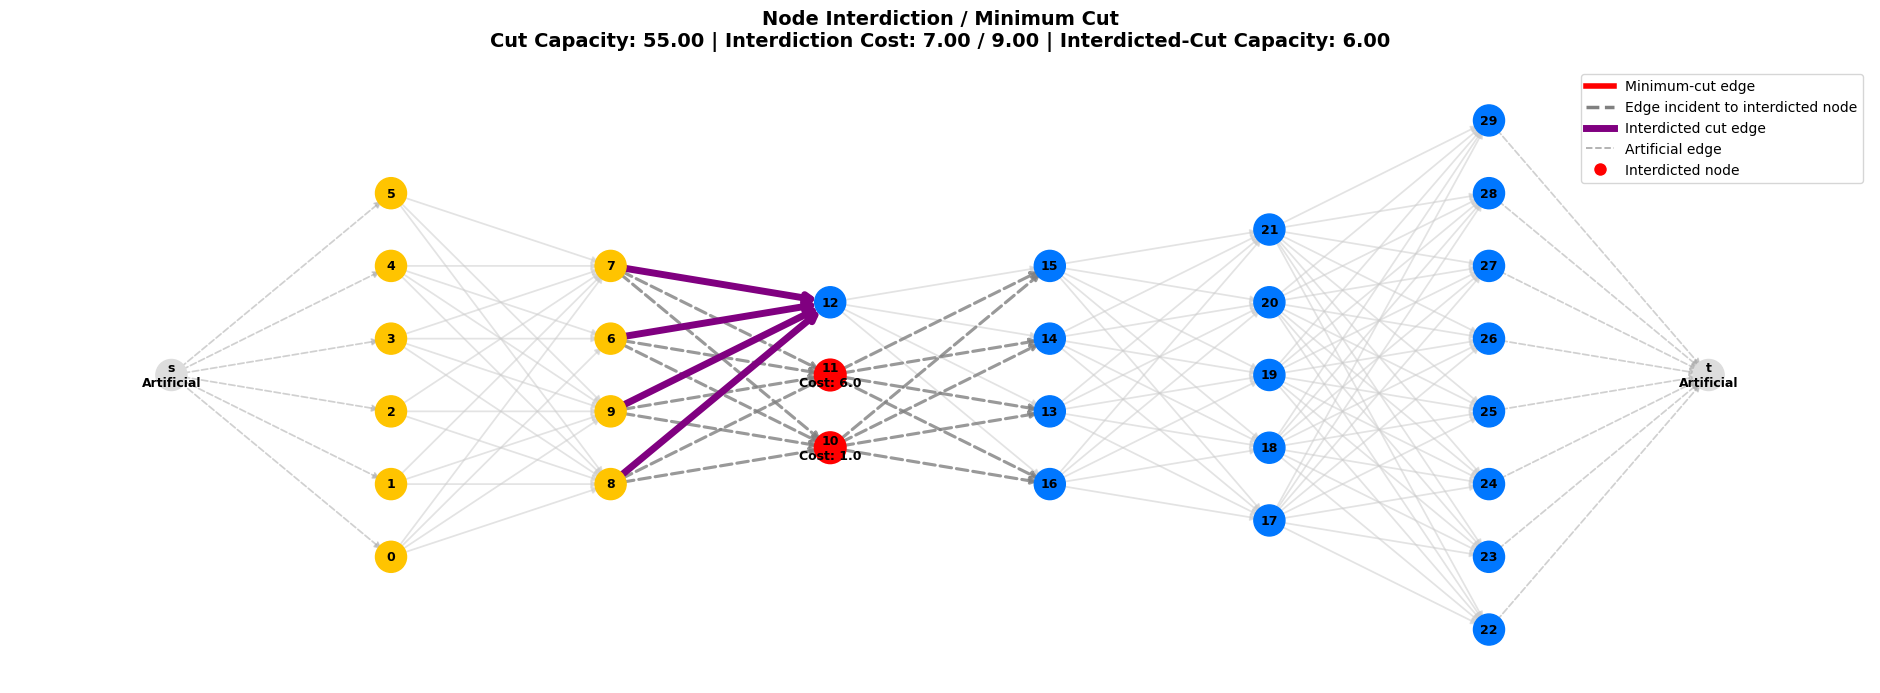

In [150]:
lp = LP(G, model_type='zerosum_mf_static_nodes')
solution = LP_Solver(lp)
vis = GraphDrawer(solution)
vis.draw(mode='interdiction')

In [151]:
lp = LP(G, model_type="max_flow")
solution = LP_Solver(lp)
analysis = LP_Analysis(solution)
#df = analysis.stochastic_analysis(200)
analysis.show_workflow()


LP_Analysis — Analysis Workflow
│
|--> Reliability
|   |--> expected_shortfall() — Estimate the expected network performance conditional on performance being below a threshold.
|   |--> failure_probability() — P(Y < threshold)
|   |--> get_component_influence() — Return separate node and edge component influence tables.
|   |--> performance_distribution() — Summarize the empirical distribution of network performance
|   |--> performance_summary() — The meta-collection of stochastic network performance
|   |--> reliability() — P(Y >= threshold)
|   |--> reliability_curve() — Construct the empirical reliability curve: R(q) = P(Y >= q)
|   |--> resilience_curve() — Resilience curves capturing expected performance as a function of component failures
|--> Cut Analysis
|   |--> get_capacity_removed() — Returns the maximum flow destroyed by the interdiction
|   |--> get_cut_capacity() — Returns the maximum flow left on the network
|   |--> get_cut_edges() — Edges belonging to the minimum cut

Interdiction effecting the capacity cut vs influence on the graph. Given $\omega_i=1, \theta_{ij} \geq 0$, however, what $\omega$ hasn't been related to is $\alpha$. $\alpha_i \leq 1-\omega_i$ disallows $\alpha_i$ to remain at 1 and continue supporting $\theta_{ij} =0$. 

$\theta_{ij} \in \{0,1\} \Rightarrow$ no continuous capacity cut (unimodularity). $z_{ij} \Rightarrow (i,j)$ is in the cut AND is operational, therefore $z_{ij} = \theta_{ij}(1-\omega_i)(1-\omega_j)$. 

Therefore, the objective function becomes $\displaystyle\sum u_{ij}z_{ij}$ with the constraints $z_{ij} \leq \theta_{ij},z_{ij} \leq 1-\omega_{i}, z_{ij} \leq 1-\omega_{j}, z_{ij} \geq \theta_{ij} - \omega_i - \omega_j$. (i.e. $z_{ij}=1 \iff \theta=1, \omega_i=0, \omega_j=0$)


Step 1: Performance distributions, Reliability, Resilience, Component influence
Step 2 (Min cut): Cut frequency, Cut persistence, Cut diversity, Bottleneck analysis
Step 3 (Interdiction): Attack surface, Interdiction efficiency, Natural failure vs adversarial failure, Capacity-loss analysis
Step 4:Same-scenario multi-formulation simulation, Cross-formulation comparison, Scenario identification, Component interaction effects
    --> Should probably be enabled as a seperate class

Step 5 (ML/graph theory): Clustering, Random forest / permutation importance, Spectral metric, Relationship between graph structure and optimization performance

100%|██████████| 50/50 [00:00<00:00, 243.18it/s]


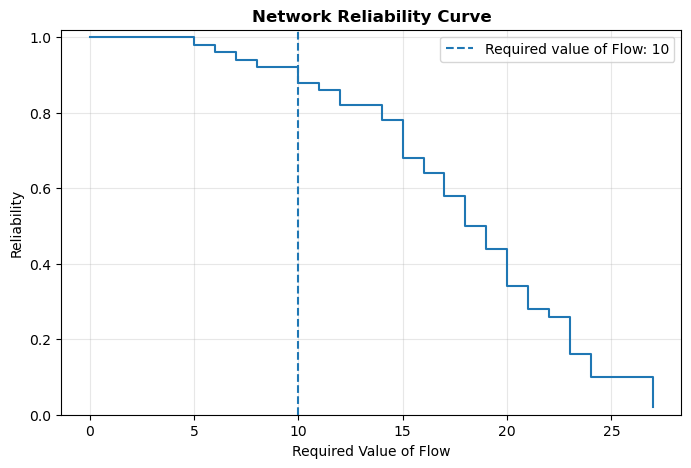

In [152]:
# Initial workflow
model_type = "max_flow"
lp = LP(G, model_type=model_type)
solution = LP_Solver(lp)
analysis = LP_Analysis(solution)

# Inspection based on problem type
analysis.summary()
analysis.get_node_results()
analysis.get_edge_results()
analysis.get_metrics()

if model_type == 'min_cut':
    analysis.get_cut_edges()
    cut_frequency = analysis.cut_frequency(df)
    cut_persistence = analysis.cut_persistence(df)
    cut_diversity = analysis.cut_diversity(df)
    bottlenecks = analysis.bottleneck_analysis(df)

if model_type == 'interdiction':
    analysis.get_interdicted_nodes()
    analysis.get_interdicted_cut_edges()
    analysis.get_interdiction_cost()
    analysis.get_interdiction_efficiency()
    attack_surface = analysis.attack_surface(df)
    efficiency = analysis.interdiction_efficiency(df)
    natural_vs_adversarial = analysis.natural_failure_vs_adversarial_failure(df)
    capacity_loss = analysis.capacity_loss(df)

# Stochastic dataframe & analysis
df = analysis.stochastic_analysis(n_sim=50,seed=123,)
analysis.performance_summary(df, y_column="objective",)
analysis.reliability(df,threshold=10,)
analysis.failure_probability(df,threshold=10,)
analysis.plot_reliability_curve(df,threshold=10,)
node_influence, edge_influence = analysis.get_component_influence(df,y_column="objective",)
reliability = analysis.get_component_reliability(df,threshold=10,)

ml = GraphML(analysis=analysis,df=df)


In [153]:
lp.g.nodes()

NodeView((0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 's', 't'))